# Load Dataset and Libraries


In [1]:
!pip install roboflow[]
%pip install ultralytics supervision roboflow
import ultralytics
ultralytics.checks()

Ultralytics 8.3.235 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Setup complete ✅ (4 CPUs, 31.4 GB RAM, 6567.3/8062.4 GB disk)


provides tools for training, validating, and deploying YOLO 

In [3]:
import os

print("data.yaml exists:", os.path.exists("/kaggle/working/Smart-city(latest)-4/data.yaml"))

data.yaml exists: True


In [4]:
print("train/images exists:", os.path.exists("/kaggle/working/Smart-city(latest)-4/train/images"))
print("valid/images exists:", os.path.exists("/kaggle/working/Smart-city(latest)-4/valid/images"))

train/images exists: True
valid/images exists: True


In [6]:
import os
from collections import defaultdict

# Dataset location
dataset_location = "/kaggle/working/Smart-city(latest)-4"

# Class names
class_names = ['DefectedManhole', 'FullBin', 'Garbage', 'GoodManhole', 'ManagedBin', 'pothole']

# Folders to check
folders = ['train', 'valid', 'test']

def count_images_and_annotations(base_path, folder):
    """Count images and annotations per class"""
    images_path = os.path.join(base_path, folder, 'images')
    labels_path = os.path.join(base_path, folder, 'labels')
    
    # Count total images
    total_images = 0
    if os.path.exists(images_path):
        total_images = len([f for f in os.listdir(images_path) 
                           if f.endswith(('.jpg', '.jpeg', '.png'))])
    
    # Count annotations per class
    class_counts = defaultdict(int)
    total_annotations = 0
    
    if os.path.exists(labels_path):
        for label_file in os.listdir(labels_path):
            if label_file.endswith('.txt'):
                label_path = os.path.join(labels_path, label_file)
                with open(label_path, 'r') as f:
                    for line in f:
                        parts = line.strip().split()
                        if parts:
                            class_id = int(parts[0])
                            if 0 <= class_id < len(class_names):
                                class_counts[class_id] += 1
                                total_annotations += 1
    
    total_label_files = len([f for f in os.listdir(labels_path) 
                            if f.endswith('.txt')]) if os.path.exists(labels_path) else 0
    
    return total_images, total_label_files, class_counts, total_annotations

# Print header
print("=" * 80)
print("DATASET ANALYSIS - Smart City Dataset")
print("=" * 80)
print(f"\nClasses: {', '.join(class_names)}\n")

# Analyze each folder
for folder in folders:
    print("=" * 80)
    print(f"{folder.upper()} SET")
    print("=" * 80)
    
    total_images, total_labels, class_counts, total_annotations = count_images_and_annotations(
        dataset_location, folder
    )
    
    print(f"\nTotal Images: {total_images}")
    print(f"Total Label Files: {total_labels}")
    print(f"Total Annotations (objects): {total_annotations}")
    
    print(f"\nAnnotations per Class:")
    print("-" * 50)
    for class_id, class_name in enumerate(class_names):
        count = class_counts.get(class_id, 0)
        percentage = (count / total_annotations * 100) if total_annotations > 0 else 0
        print(f"  {class_name:20s}: {count:5d} ({percentage:5.2f}%)")
    
    print()

# Overall summary
print("=" * 80)
print("OVERALL SUMMARY")
print("=" * 80)

total_all_images = 0
total_all_annotations = 0
overall_class_counts = defaultdict(int)

for folder in folders:
    total_images, _, class_counts, total_annotations = count_images_and_annotations(
        dataset_location, folder
    )
    total_all_images += total_images
    total_all_annotations += total_annotations
    
    for class_id, count in class_counts.items():
        overall_class_counts[class_id] += count

print(f"\nTotal Images (all sets): {total_all_images}")
print(f"Total Annotations (all sets): {total_all_annotations}")

print(f"\nTotal Annotations per Class (across all sets):")
print("-" * 50)
for class_id, class_name in enumerate(class_names):
    count = overall_class_counts.get(class_id, 0)
    percentage = (count / total_all_annotations * 100) if total_all_annotations > 0 else 0
    print(f"  {class_name:20s}: {count:5d} ({percentage:5.2f}%)")

print("\n" + "=" * 80)

DATASET ANALYSIS - Smart City Dataset

Classes: DefectedManhole, FullBin, Garbage, GoodManhole, ManagedBin, pothole

TRAIN SET

Total Images: 2710
Total Label Files: 2710
Total Annotations (objects): 4614

Annotations per Class:
--------------------------------------------------
  DefectedManhole     :   574 (12.44%)
  FullBin             :   743 (16.10%)
  Garbage             :   973 (21.09%)
  GoodManhole         :   703 (15.24%)
  ManagedBin          :   739 (16.02%)
  pothole             :   882 (19.12%)

VALID SET

Total Images: 586
Total Label Files: 586
Total Annotations (objects): 1041

Annotations per Class:
--------------------------------------------------
  DefectedManhole     :   138 (13.26%)
  FullBin             :   178 (17.10%)
  Garbage             :   199 (19.12%)
  GoodManhole         :   148 (14.22%)
  ManagedBin          :   156 (14.99%)
  pothole             :   222 (21.33%)

TEST SET

Total Images: 578
Total Label Files: 578
Total Annotations (objects): 1002

Ann

# Train yolo11s model training


Ultralytics 8.3.235 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/Smart-city(latest)-4/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.1, dynamic=False, embed=None, epochs=250, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.001, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=monitoring-yolo11s-improved, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=Tr

invalid value encountered in less
invalid value encountered in less


                   all        586       1040      0.736      0.706      0.705      0.492
       DefectedManhole        117        138      0.785       0.82       0.84      0.606
               FullBin        101        178      0.706      0.612      0.552      0.339
               Garbage        149        199      0.572      0.457      0.458      0.235
           GoodManhole        117        148      0.723      0.811      0.759       0.56
            ManagedBin        111        155        0.8       0.71      0.756      0.548
               pothole        116        222      0.829      0.824      0.868      0.661
Speed: 0.1ms preprocess, 4.6ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /kaggle/working/runs/detect/monitoring-yolo11s-improved

✅ TRAINING COMPLETE!

⏱️  Total Training Time: 227.66 minutes (13659.84 seconds)
📈 Completed all epochs

📊 Best Validation Metrics:
   • mAP@[.5:.95]: 0.4916
   • mAP@0.5:      0.7053
   • mAP@0.75:     0.5461

💾 Best Mod

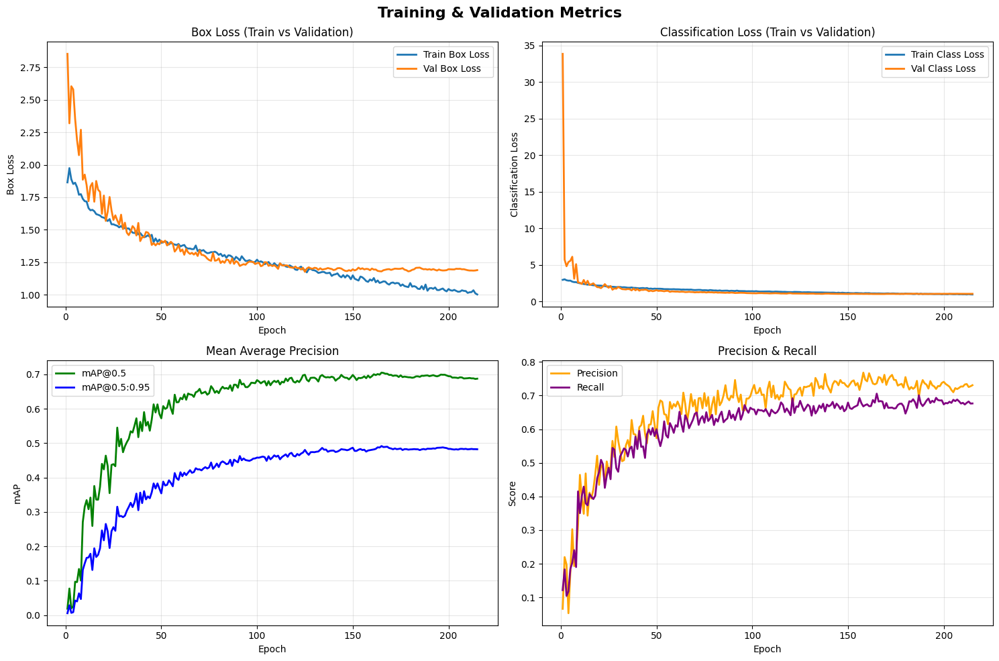


2️⃣ Plotting Precision, Recall, F1-Score Trends...
   ✓ Saved: runs/detect/monitoring-yolo11s-improved/precision_recall_f1_trends.png


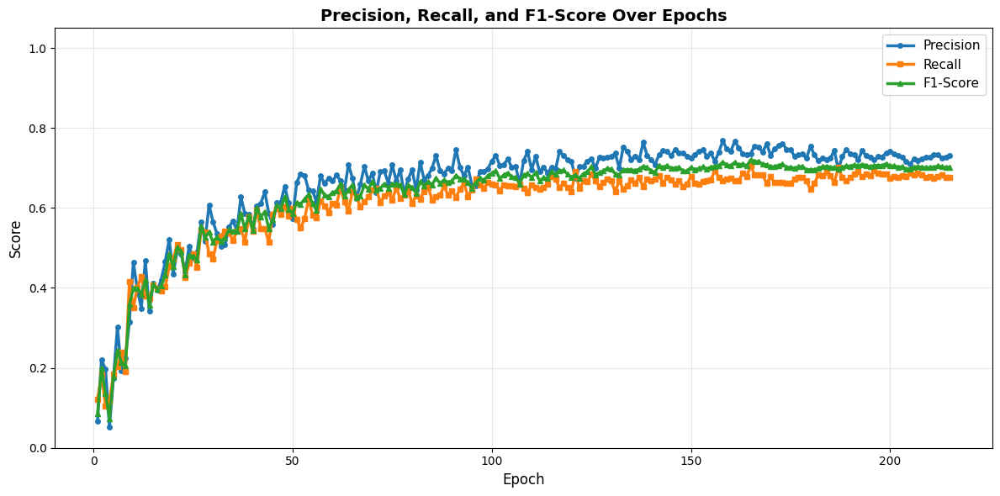


3️⃣ Generating Confusion Matrix...
   ✓ Confusion matrix already generated: runs/detect/monitoring-yolo11s-improved/confusion_matrix.png


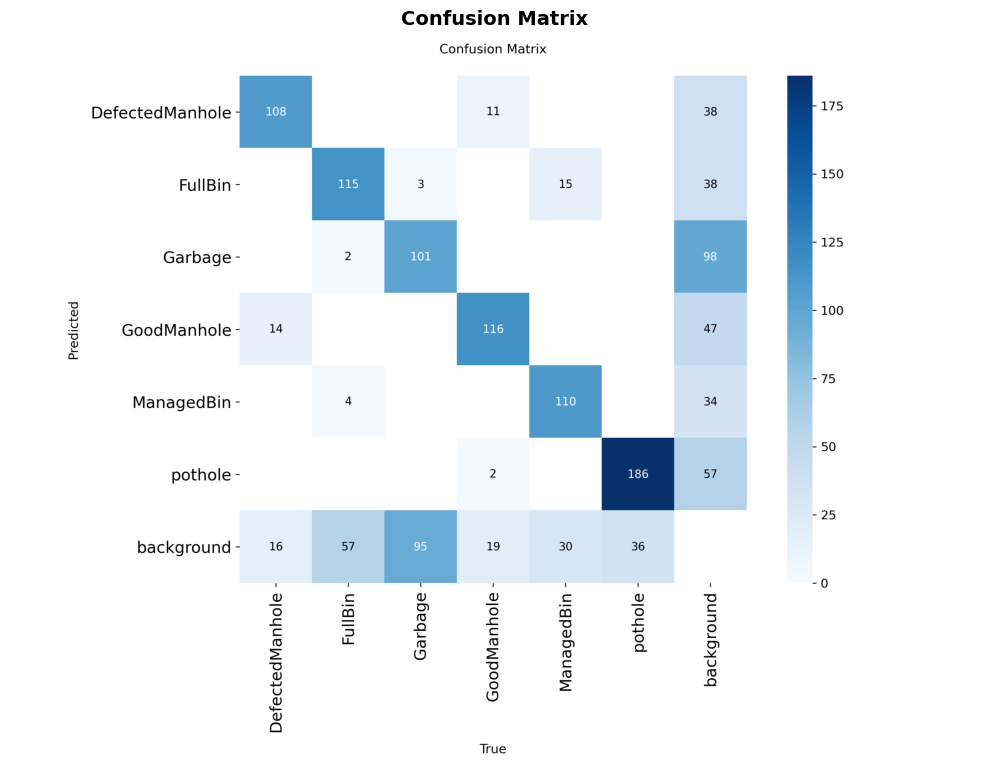


4️⃣ Running Evaluation on Test Set...
Ultralytics 8.3.235 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2223.7±1283.0 MB/s, size: 709.1 KB)
val: Scanning /kaggle/working/Smart-city(latest)-4/test/labels... 578 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 578/578 1.5Kit/s 0.4s
val: /kaggle/working/Smart-city(latest)-4/test/images/dumpsters-being-full-garbage-260nw-272587109_webp.rf.59812b331c4c84025cf221b89a7fff5d.jpg: 1 duplicate labels removed
val: New cache created: /kaggle/working/Smart-city(latest)-4/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 101, len(boxes) = 1001. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     I

invalid value encountered in less
invalid value encountered in less


                   all        578       1001       0.77      0.679      0.746      0.559
       DefectedManhole        114        124      0.882      0.806      0.884      0.692
               FullBin         99        156      0.732      0.551      0.661      0.476
               Garbage        142        211      0.651      0.417       0.51      0.266
           GoodManhole        115        147      0.783      0.789      0.805      0.624
            ManagedBin        108        163      0.746      0.687      0.729       0.56
               pothole        117        200      0.829      0.825      0.888      0.738
Speed: 1.6ms preprocess, 6.2ms inference, 0.0ms loss, 1.4ms postprocess per image
Saving /kaggle/working/runs/detect/val/predictions.json...
Results saved to /kaggle/working/runs/detect/val

5️⃣ Creating Comprehensive Evaluation Metrics Table...

📊 COMPREHENSIVE EVALUATION METRICS (Test Set)
          Class  Precision  Recall  F1-Score  mAP@0.5  mAP@0.5:0.95
DefectedManhole 

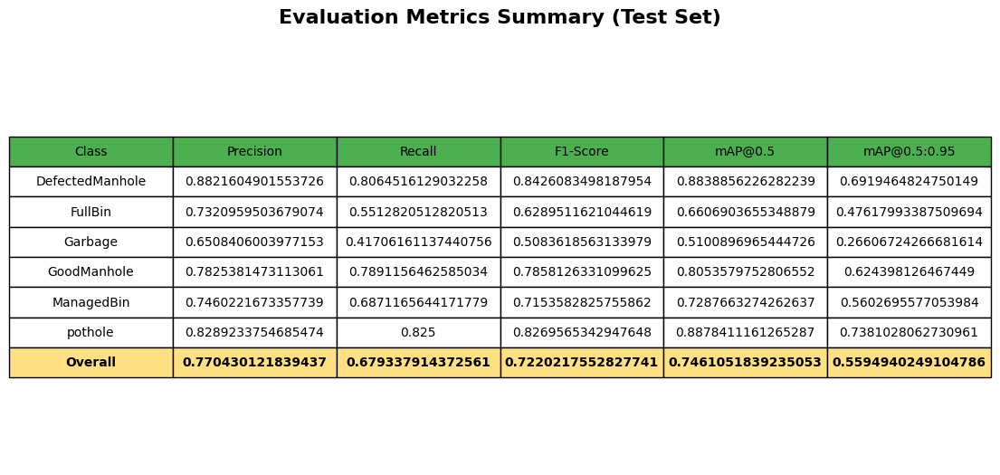


6️⃣ Note: ROC curves are typically used for binary classification.
   For multi-class object detection, we use Precision-Recall curves instead.
   Check the generated PR curves in the results folder.

✅ ALL VISUALIZATIONS COMPLETED!

📁 All results saved in: runs/detect/monitoring-yolo11s-improved/

Generated files:
   • training_validation_curves.png
   • precision_recall_f1_trends.png
   • confusion_matrix.png
   • evaluation_metrics_table.png
   • PR_curve.png (auto-generated)
   • F1_curve.png (auto-generated)


In [7]:
from ultralytics import YOLO
import time

# Load the pre-trained YOLOv11s model
model = YOLO("yolo11s.pt")

# Start timer
start_time = time.time()

# ===================================================================
# 🚀 IMPROVED TRAINING with Strong Augmentation & Early Stopping
# ===================================================================

results = model.train(
    data=f"{dataset.location}/data.yaml",
    
    # ===== Basic Training Parameters =====
    epochs=250,                    # More epochs with early stopping
    imgsz=640,
    batch=16,
    device=0,
    name="monitoring-yolo11s-improved",
    verbose=True,
    
    # ===== Early Stopping (Overfitting Prevention) =====
    patience=50,                   # Stop if no improvement for 30 epochs
    
    # ===== Learning Rate & Optimizer =====
    lr0=0.01,                      # Initial learning rate
    lrf=0.001,                     # Final learning rate (for cosine annealing)
    optimizer='AdamW',             # Better than SGD for small datasets
    cos_lr=True,                   # Enable Cosine Annealing LR schedule
    warmup_epochs=10,              # More warmup (default is 3)
    warmup_momentum=0.5,           # Warmup momentum
    
    # ===== Regularization =====
    weight_decay=0.001,            # L2 regularization (increased from 0.0005)
    dropout=0.1,                   # Dropout for overfitting prevention
    
    # ===== Data Augmentation (STRONG) =====
    hsv_h=0.015,                   # HSV-Hue augmentation
    hsv_s=0.7,                     # HSV-Saturation augmentation
    hsv_v=0.4,                     # HSV-Value augmentation
    degrees=10.0,                  # Rotation augmentation
    translate=0.1,                 # Translation augmentation
    scale=0.5,                     # Scale augmentation (0.5 = ±50%)
    shear=0.0,                     # Shear augmentation
    perspective=0.0001,            # Perspective augmentation
    flipud=0.0,                    # Vertical flip probability
    fliplr=0.5,                    # Horizontal flip probability
    mosaic=1.0,                    # Mosaic augmentation (ENABLED - Very Important!)
    mixup=0.15,                    # MixUp augmentation (15% probability)
    copy_paste=0.1,                # Copy-paste augmentation (10% probability)
    erasing=0.4,                   # Random erasing augmentation
    
    # ===== Loss Function Weights =====
    box=7.5,                       # Box loss gain
    cls=0.5,                       # Class loss gain  
    dfl=1.5,                       # DFL loss gain
    
    # ===== Model Saving =====
    save=True,                     # Save checkpoints
    save_period=10,                # Save every 10 epochs
    
    # ===== Validation =====
    val=True,                      # Enable validation
    plots=True,                    # Save training plots
)

# End timer
end_time = time.time()
training_time = end_time - start_time

# ===================================================================
# 📊 TRAINING SUMMARY
# ===================================================================

print("\n" + "="*70)
print("✅ TRAINING COMPLETE!")
print("="*70)

print(f"\n⏱️  Total Training Time: {training_time/60:.2f} minutes ({training_time:.2f} seconds)")

# Get the best epoch info
if hasattr(results, 'best_epoch'):
    print(f"🏆 Best Epoch: {results.best_epoch}")
    print(f"⚠️  Training stopped at epoch: {results.epochs} (Early stopping activated)")
else:
    print(f"📈 Completed all epochs")

# Metrics
if hasattr(results, "box") and results.box.map is not None:
    print(f"\n📊 Best Validation Metrics:")
    print(f"   • mAP@[.5:.95]: {results.box.map:.4f}")
    print(f"   • mAP@0.5:      {results.box.map50:.4f}")
    print(f"   • mAP@0.75:     {results.box.map75:.4f}")

# Model location
print(f"\n💾 Best Model Saved At:")
print(f"   runs/detect/monitoring-yolo11s-improved/weights/best.pt")

print("\n" + "="*70)
print("🔥 IMPROVEMENTS APPLIED:")
print("="*70)
print("✓ Strong Data Augmentation (Mosaic + MixUp + Erasing)")
print("✓ Cosine Annealing LR Schedule")
print("✓ Extended Warmup (10 epochs)")
print("✓ Increased Weight Decay (0.001)")
print("✓ Early Stopping (patience=30)")
print("✓ AdamW Optimizer")
print("✓ Enhanced Loss Weights (box=7.5, cls=0.5, dfl=1.5)")
print("="*70)

print("\n💡 NOTE: Class weighting handled through loss function weights")
print("   Poor performing classes (Garbage, FullBin) will benefit from:")
print("   • Strong augmentation (especially Mosaic & Erasing)")
print("   • Higher box loss weight (7.5) for better localization")
print("   • More training epochs with early stopping")

# ===================================================================
# 📈 DETAILED VISUALIZATION & EVALUATION
# ===================================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, roc_curve, auc
import seaborn as sns
import pandas as pd
import glob

print("\n" + "="*70)
print("📊 GENERATING DETAILED VISUALIZATIONS...")
print("="*70)

# Get the results directory
results_dir = "runs/detect/monitoring-yolo11s-improved"

# ===== 1. TRAINING & VALIDATION CURVES =====
print("\n1️⃣ Plotting Training & Validation Curves...")

# Load results.csv
results_csv = f"{results_dir}/results.csv"
if os.path.exists(results_csv):
    df = pd.read_csv(results_csv)
    df.columns = df.columns.str.strip()  # Remove whitespace from column names
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle('Training & Validation Metrics', fontsize=16, fontweight='bold')
    
    # Loss curves
    axes[0, 0].plot(df['epoch'], df['train/box_loss'], label='Train Box Loss', linewidth=2)
    axes[0, 0].plot(df['epoch'], df['val/box_loss'], label='Val Box Loss', linewidth=2)
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Box Loss')
    axes[0, 0].set_title('Box Loss (Train vs Validation)')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    axes[0, 1].plot(df['epoch'], df['train/cls_loss'], label='Train Class Loss', linewidth=2)
    axes[0, 1].plot(df['epoch'], df['val/cls_loss'], label='Val Class Loss', linewidth=2)
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Classification Loss')
    axes[0, 1].set_title('Classification Loss (Train vs Validation)')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # mAP curves
    axes[1, 0].plot(df['epoch'], df['metrics/mAP50(B)'], label='mAP@0.5', linewidth=2, color='green')
    axes[1, 0].plot(df['epoch'], df['metrics/mAP50-95(B)'], label='mAP@0.5:0.95', linewidth=2, color='blue')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('mAP')
    axes[1, 0].set_title('Mean Average Precision')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # Precision & Recall
    axes[1, 1].plot(df['epoch'], df['metrics/precision(B)'], label='Precision', linewidth=2, color='orange')
    axes[1, 1].plot(df['epoch'], df['metrics/recall(B)'], label='Recall', linewidth=2, color='purple')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Score')
    axes[1, 1].set_title('Precision & Recall')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f"{results_dir}/training_validation_curves.png", dpi=300, bbox_inches='tight')
    print(f"   ✓ Saved: {results_dir}/training_validation_curves.png")
    plt.show()

# ===== 2. PRECISION, RECALL, F1-SCORE LINE GRAPHS =====
print("\n2️⃣ Plotting Precision, Recall, F1-Score Trends...")

if os.path.exists(results_csv):
    fig, ax = plt.subplots(1, 1, figsize=(12, 6))
    
    precision = df['metrics/precision(B)']
    recall = df['metrics/recall(B)']
    f1_score = 2 * (precision * recall) / (precision + recall + 1e-6)
    
    ax.plot(df['epoch'], precision, label='Precision', linewidth=2.5, marker='o', markersize=4)
    ax.plot(df['epoch'], recall, label='Recall', linewidth=2.5, marker='s', markersize=4)
    ax.plot(df['epoch'], f1_score, label='F1-Score', linewidth=2.5, marker='^', markersize=4)
    
    ax.set_xlabel('Epoch', fontsize=12)
    ax.set_ylabel('Score', fontsize=12)
    ax.set_title('Precision, Recall, and F1-Score Over Epochs', fontsize=14, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0, 1.05])
    
    plt.tight_layout()
    plt.savefig(f"{results_dir}/precision_recall_f1_trends.png", dpi=300, bbox_inches='tight')
    print(f"   ✓ Saved: {results_dir}/precision_recall_f1_trends.png")
    plt.show()

# ===== 3. CONFUSION MATRIX =====
print("\n3️⃣ Generating Confusion Matrix...")

# Check if confusion matrix already exists
confusion_matrix_img = glob.glob(f"{results_dir}/confusion_matrix*.png")
if confusion_matrix_img:
    print(f"   ✓ Confusion matrix already generated: {confusion_matrix_img[0]}")
    from PIL import Image
    img = Image.open(confusion_matrix_img[0])
    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("   ⚠ Confusion matrix will be generated after validation")

# ===== 4. EVALUATION ON TEST SET =====
print("\n4️⃣ Running Evaluation on Test Set...")

# Load best model
best_model = YOLO(f"{results_dir}/weights/best.pt")

# Evaluate on test set
test_results = best_model.val(
    data=f"{dataset.location}/data.yaml",
    split='test',
    device=0,
    plots=True,
    save_json=True,
    conf=0.25,
    iou=0.6
)

# ===== 5. COMPREHENSIVE EVALUATION METRICS TABLE =====
print("\n5️⃣ Creating Comprehensive Evaluation Metrics Table...")

class_names = ['DefectedManhole', 'FullBin', 'Garbage', 'GoodManhole', 'ManagedBin', 'pothole']

# Create results dataframe
eval_data = {
    'Class': class_names + ['Overall'],
    'Precision': [],
    'Recall': [],
    'F1-Score': [],
    'mAP@0.5': [],
    'mAP@0.5:0.95': []
}

# Get per-class metrics
if hasattr(test_results, 'box'):
    # Per-class metrics
    for i in range(len(class_names)):
        if hasattr(test_results.box, 'p') and len(test_results.box.p) > i:
            precision = test_results.box.p[i]
        else:
            precision = 0
            
        if hasattr(test_results.box, 'r') and len(test_results.box.r) > i:
            recall = test_results.box.r[i]
        else:
            recall = 0
            
        f1 = 2 * (precision * recall) / (precision + recall + 1e-6)
        
        if hasattr(test_results.box, 'ap50') and len(test_results.box.ap50) > i:
            map50 = test_results.box.ap50[i]
        else:
            map50 = 0
            
        if hasattr(test_results.box, 'ap') and len(test_results.box.ap) > i:
            map50_95 = test_results.box.ap[i]
        else:
            map50_95 = 0
        
        eval_data['Precision'].append(precision)
        eval_data['Recall'].append(recall)
        eval_data['F1-Score'].append(f1)
        eval_data['mAP@0.5'].append(map50)
        eval_data['mAP@0.5:0.95'].append(map50_95)
    
    # Overall metrics
    eval_data['Precision'].append(test_results.box.mp if hasattr(test_results.box, 'mp') else 0)
    eval_data['Recall'].append(test_results.box.mr if hasattr(test_results.box, 'mr') else 0)
    eval_data['F1-Score'].append(2 * (eval_data['Precision'][-1] * eval_data['Recall'][-1]) / 
                                  (eval_data['Precision'][-1] + eval_data['Recall'][-1] + 1e-6))
    eval_data['mAP@0.5'].append(test_results.box.map50 if hasattr(test_results.box, 'map50') else 0)
    eval_data['mAP@0.5:0.95'].append(test_results.box.map if hasattr(test_results.box, 'map') else 0)

eval_df = pd.DataFrame(eval_data)

# Display table
print("\n" + "="*90)
print("📊 COMPREHENSIVE EVALUATION METRICS (Test Set)")
print("="*90)
print(eval_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print("="*90)

# Save table as image
fig, ax = plt.subplots(figsize=(14, 6))
ax.axis('tight')
ax.axis('off')

table = ax.table(cellText=eval_df.values, colLabels=eval_df.columns,
                cellLoc='center', loc='center',
                colColours=['#4CAF50']*len(eval_df.columns))

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)

# Highlight overall row
for i in range(len(eval_df.columns)):
    table[(len(class_names)+1, i)].set_facecolor('#FFE082')
    table[(len(class_names)+1, i)].set_text_props(weight='bold')

plt.title('Evaluation Metrics Summary (Test Set)', fontsize=16, fontweight='bold', pad=20)
plt.savefig(f"{results_dir}/evaluation_metrics_table.png", dpi=300, bbox_inches='tight')
print(f"\n   ✓ Saved: {results_dir}/evaluation_metrics_table.png")
plt.show()

# ===== 6. ROC CURVES (if available) =====
print("\n6️⃣ Note: ROC curves are typically used for binary classification.")
print("   For multi-class object detection, we use Precision-Recall curves instead.")
print("   Check the generated PR curves in the results folder.")

print("\n" + "="*70)
print("✅ ALL VISUALIZATIONS COMPLETED!")
print("="*70)
print(f"\n📁 All results saved in: {results_dir}/")
print("\nGenerated files:")
print("   • training_validation_curves.png")
print("   • precision_recall_f1_trends.png")
print("   • confusion_matrix.png")
print("   • evaluation_metrics_table.png")
print("   • PR_curve.png (auto-generated)")
print("   • F1_curve.png (auto-generated)")
print("="*70)


image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/potholes487_png_jpg.rf.c9b8f2ae4904dda49524b01bf0f80942.jpg: 640x640 1 pothole, 10.2ms
Speed: 1.7ms preprocess, 10.2ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


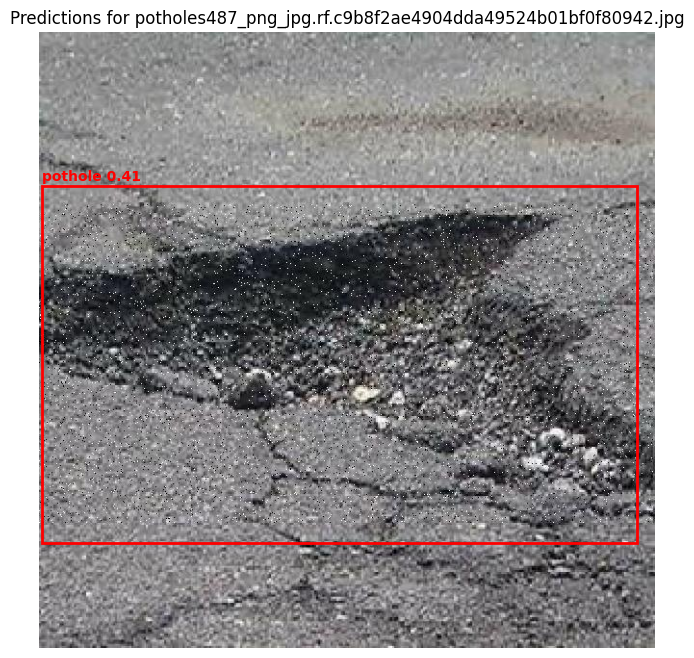


image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/0745_jpg.rf.6b4c6202dfe9a859b3b076ba0e7ad54f.jpg: 640x640 1 DefectedManhole, 1 GoodManhole, 10.4ms
Speed: 1.6ms preprocess, 10.4ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


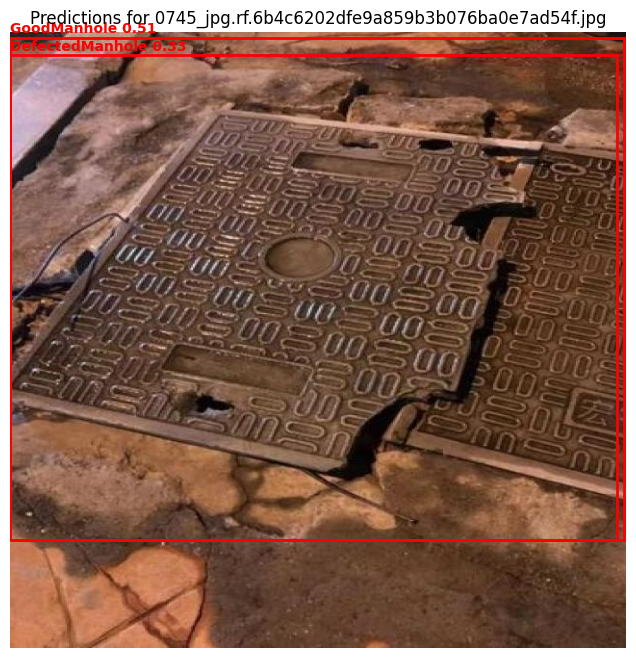


image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/IMG_20250821_174347_jpg.rf.f008b83a9ecfe28da3f75176158fe9c3.jpg: 640x480 1 ManagedBin, 49.0ms
Speed: 3.0ms preprocess, 49.0ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)


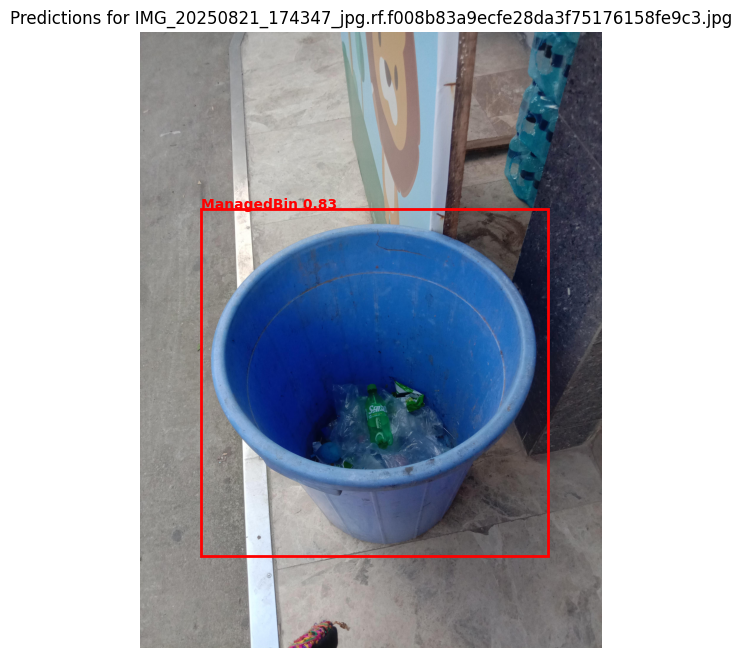


image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/potholes500_png_jpg.rf.9cc5cdfc1f290ce12ff286de174ea03a.jpg: 640x640 1 pothole, 10.3ms
Speed: 1.7ms preprocess, 10.3ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)


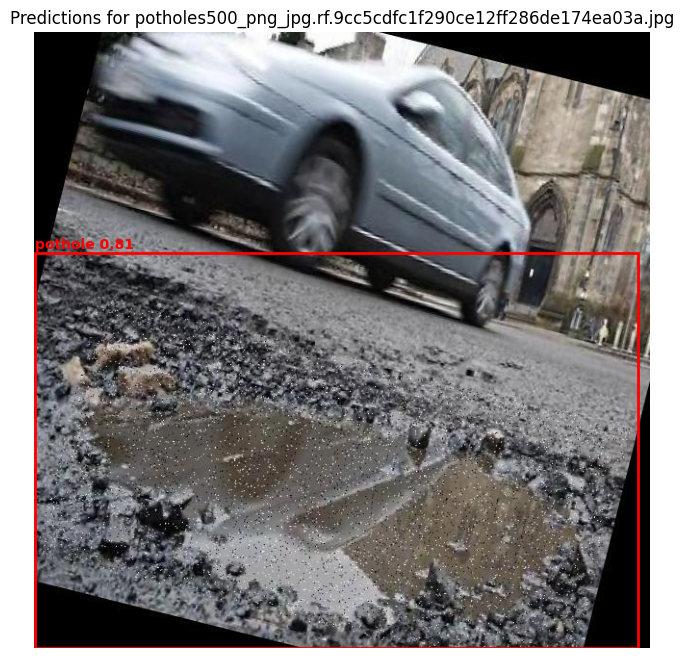


image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/IMG_20250818_103548_jpg.rf.30aa2c2f979fbd003fded1be1c9d3e3a.jpg: 640x480 1 Garbage, 2 ManagedBins, 9.8ms
Speed: 3.0ms preprocess, 9.8ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)


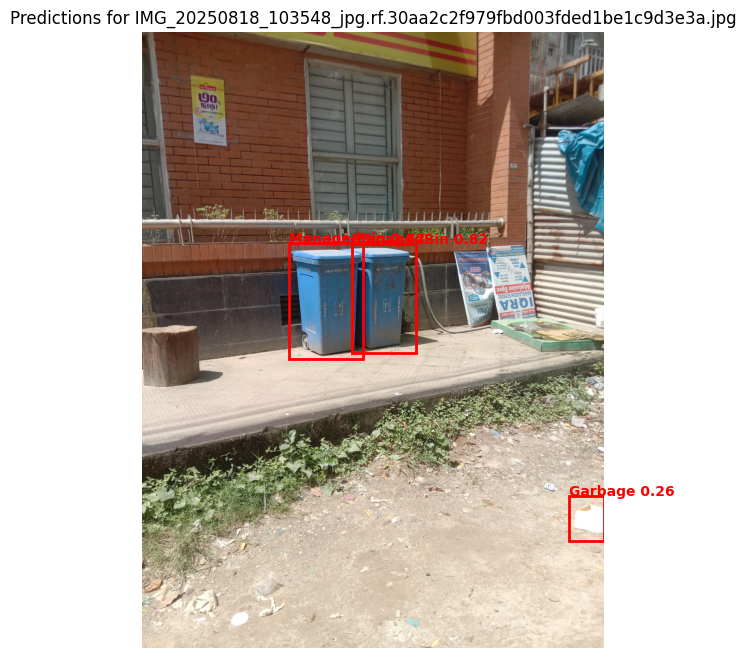


image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/potholes92_png_jpg.rf.f3d1ee199d03269085d5f2e3249cdae0.jpg: 640x640 1 Garbage, 1 pothole, 10.1ms
Speed: 1.6ms preprocess, 10.1ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)


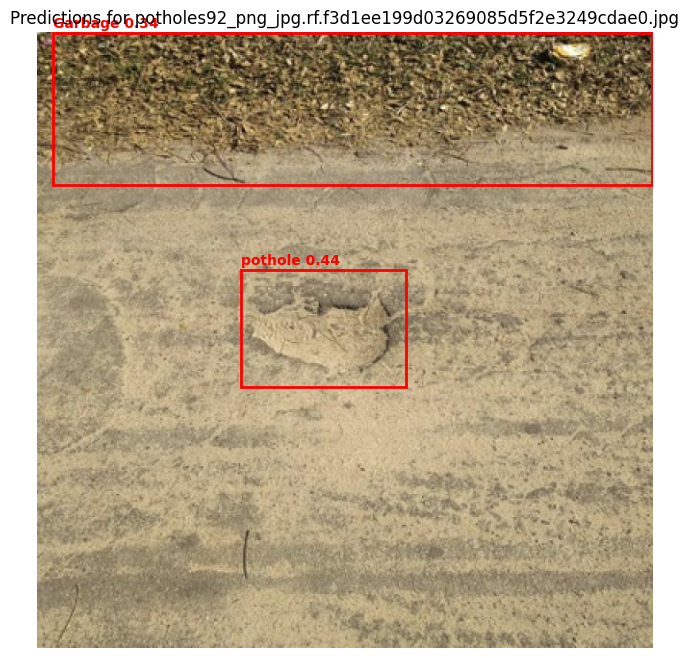


image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/fc15_0916_jpg.rf.9e6a48cf488ceb3735c4f70463c8f716.jpg: 640x640 1 DefectedManhole, 9.7ms
Speed: 1.6ms preprocess, 9.7ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)


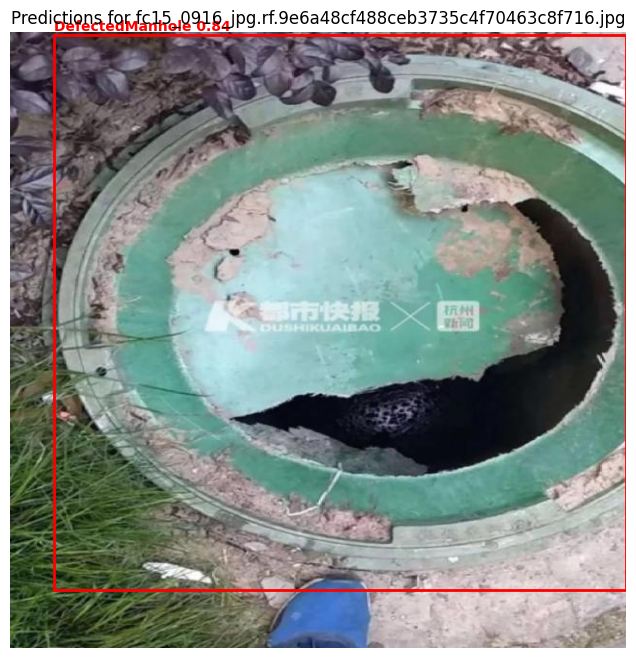


image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/fc15_3577_jpg.rf.5ea0621874889e1f2e883ffb36979458.jpg: 640x640 1 DefectedManhole, 10.5ms
Speed: 1.6ms preprocess, 10.5ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)


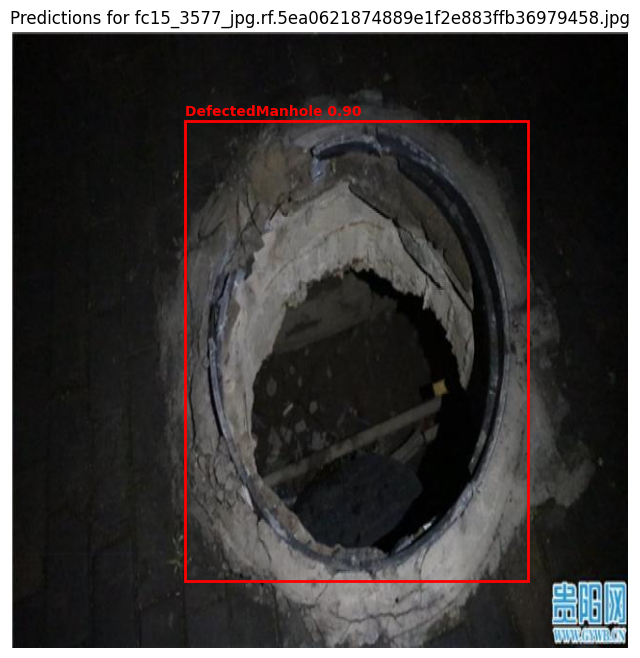


image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/1191_jpg.rf.d4c2b284fe40cb76b1ee7916b55294f0.jpg: 640x640 1 GoodManhole, 9.5ms
Speed: 1.5ms preprocess, 9.5ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)


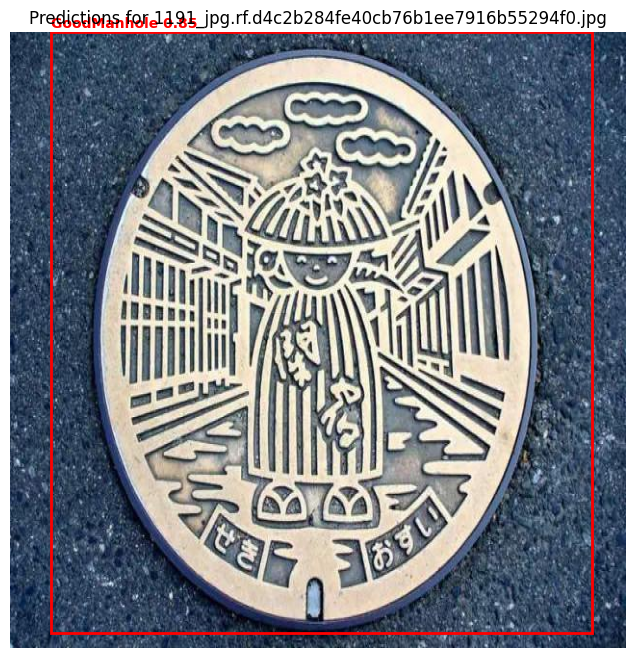


image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/fc15_0628_jpg.rf.ec6b3e6360a2c9f9ac6cea83ecea436e.jpg: 640x640 1 DefectedManhole, 9.2ms
Speed: 1.5ms preprocess, 9.2ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)


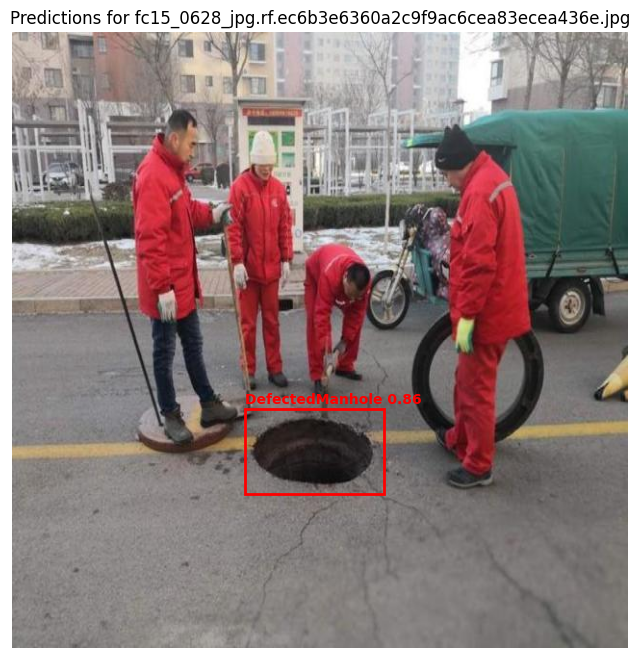

In [8]:
import random
import os
from ultralytics import YOLO
import matplotlib.pyplot as plt
from PIL import Image

# ===== 1. Load the trained model =====
results_dir = "runs/detect/monitoring-yolo11s-improved"
best_model = YOLO(f"{results_dir}/weights/best.pt")

# ===== 2. Get test images =====
test_images_dir = os.path.join(dataset.location, "test/images")  # Update path if different
all_images = [os.path.join(test_images_dir, img) for img in os.listdir(test_images_dir) if img.endswith(('.jpg', '.png', '.jpeg'))]

# Pick 10 random images
random_images = random.sample(all_images, 10)

# ===== 3. Run predictions =====
for img_path in random_images:
    results = best_model.predict(img_path, conf=0.25, iou=0.6, save=False)  # save=True if you want saved images

    # ===== 4. Visualize predictions =====
    img = Image.open(img_path)
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Predictions for {os.path.basename(img_path)}", fontsize=12)

    # Draw bounding boxes from results
    for box in results[0].boxes:  # results[0].boxes contains all detected boxes
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        cls = int(box.cls[0].cpu().numpy())
        conf = float(box.conf[0].cpu().numpy())
        label = f"{best_model.model.names[cls]} {conf:.2f}"

        plt.gca().add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, edgecolor='red', facecolor='none', linewidth=2))
        plt.text(x1, y1-5, label, color='red', fontsize=10, weight='bold')

    plt.show()



📌 Generating Random Predictions...

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/Copy-of-IMG_20250702_112830_jpg.rf.eae14e9679364f55e7896a640a8831f5.jpg: 640x480 1 Garbage, 1 ManagedBin, 9.5ms
Speed: 2.9ms preprocess, 9.5ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)


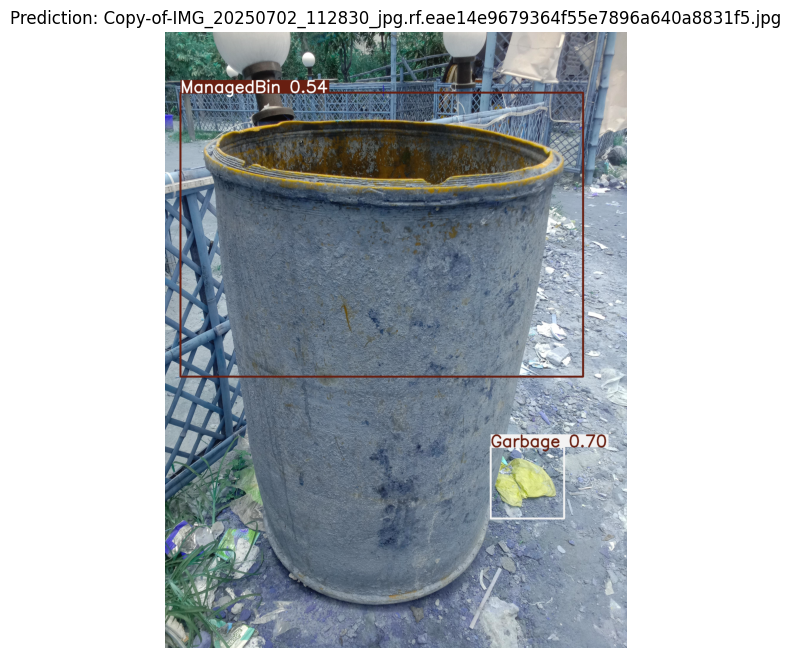

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/Copy-of-IMG_20250702_112830_jpg.rf.eae14e9679364f55e7896a640a8831f5.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/image-387-_jpg.rf.830bda15286d71c201315950972e1f8a.jpg: 640x480 1 FullBin, 9.3ms
Speed: 2.3ms preprocess, 9.3ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)


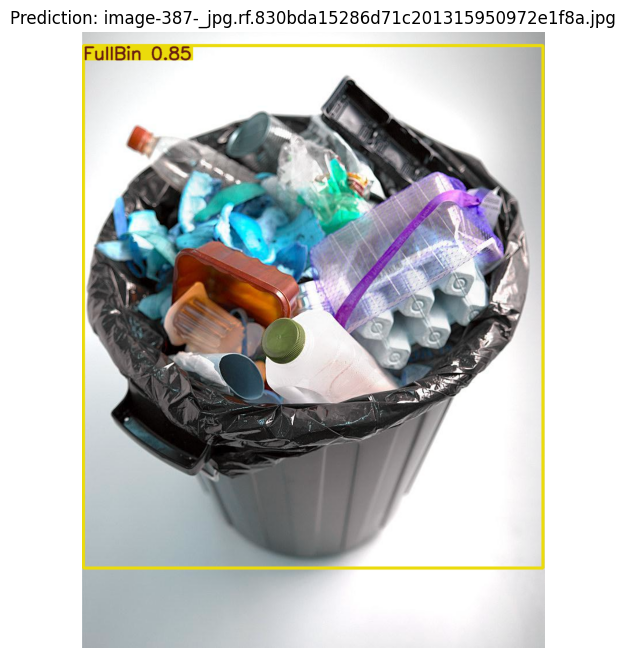

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/image-387-_jpg.rf.830bda15286d71c201315950972e1f8a.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/image21_jpg.rf.c7a1576fb88c9bf6e414360dfaed33ec.jpg: 640x640 1 FullBin, 2 Garbages, 9.9ms
Speed: 1.5ms preprocess, 9.9ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


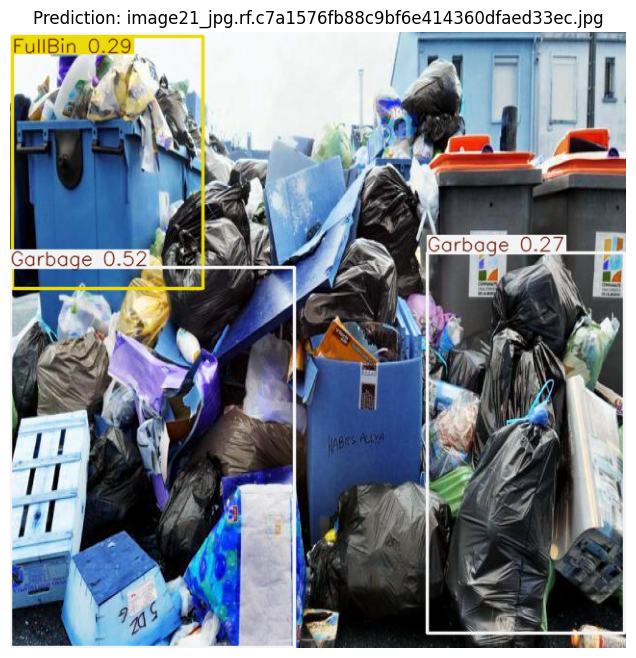

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/image21_jpg.rf.c7a1576fb88c9bf6e414360dfaed33ec.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/-_907_jpg.rf.353c9e73d259a976b1fcfc2f1612efff.jpg: 640x640 1 GoodManhole, 9.6ms
Speed: 1.6ms preprocess, 9.6ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


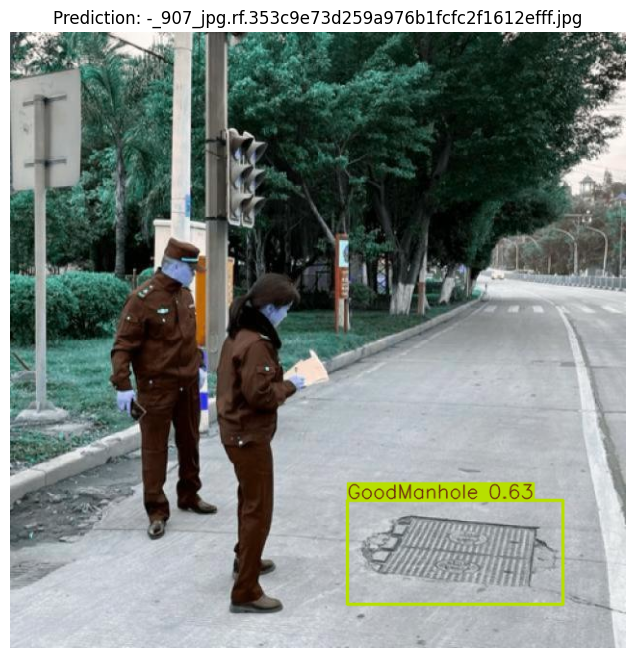

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/-_907_jpg.rf.353c9e73d259a976b1fcfc2f1612efff.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/potholes409_png_jpg.rf.6ca40e7699a45f39cf78a5b98ecf929d.jpg: 640x640 3 potholes, 11.1ms
Speed: 1.8ms preprocess, 11.1ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


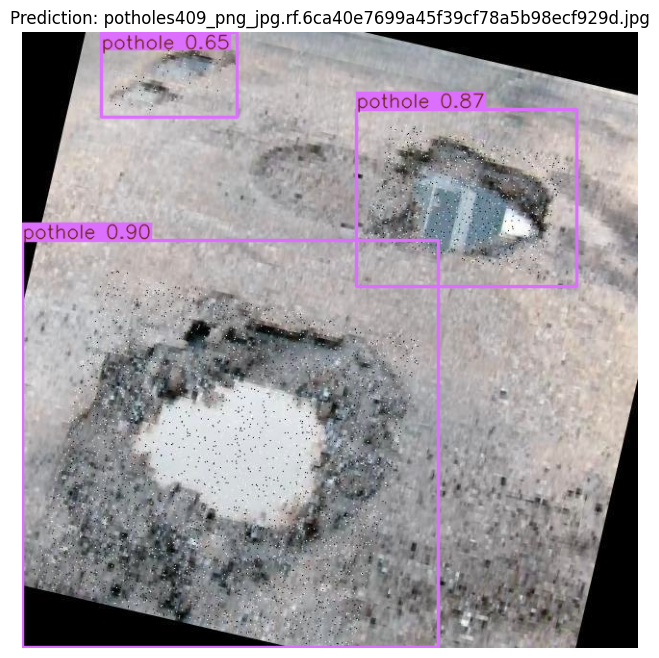

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/potholes409_png_jpg.rf.6ca40e7699a45f39cf78a5b98ecf929d.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/IMG_20250821_171653_jpg.rf.7dbcc76ab73b840893f9acc4de884879.jpg: 640x480 1 ManagedBin, 10.3ms
Speed: 3.2ms preprocess, 10.3ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 480)


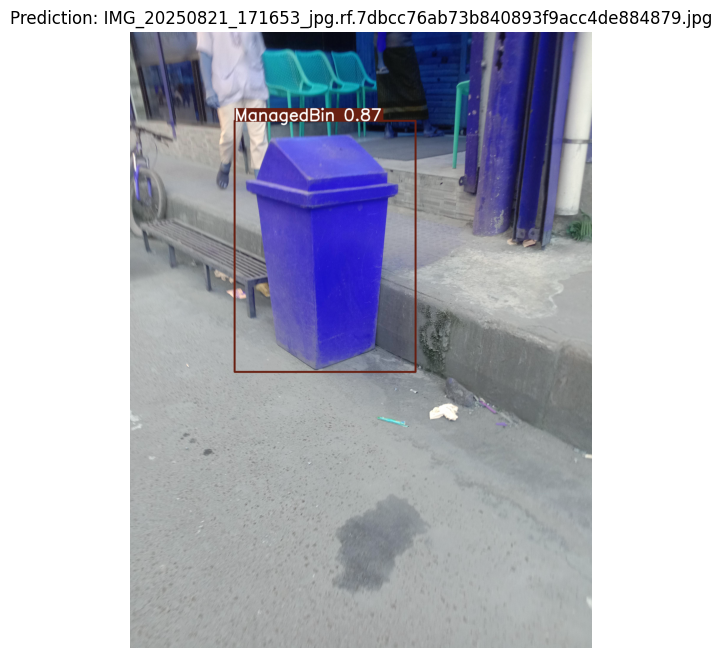

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/IMG_20250821_171653_jpg.rf.7dbcc76ab73b840893f9acc4de884879.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/0844_jpg.rf.c2758a34cdc2456460e5cd33edeb68b4.jpg: 640x640 1 DefectedManhole, 9.9ms
Speed: 1.6ms preprocess, 9.9ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)


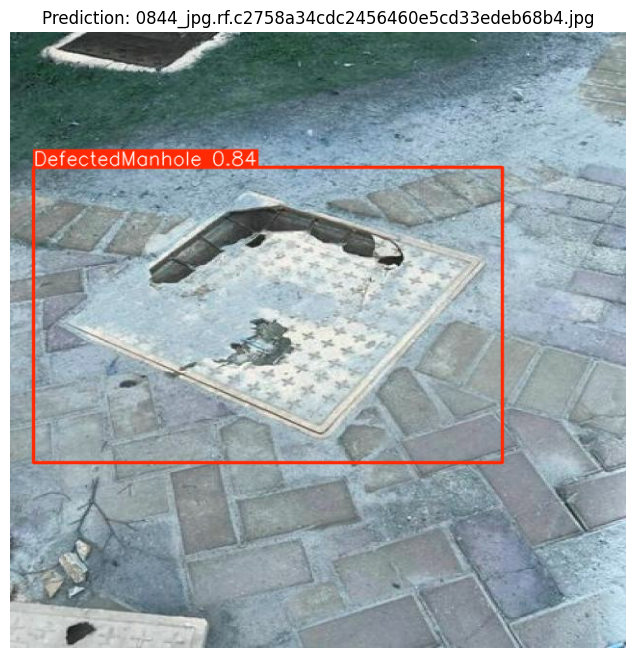

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/0844_jpg.rf.c2758a34cdc2456460e5cd33edeb68b4.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/IMG_20251014_170423_jpg.rf.99ad90a1481d7d5421ff05d1b5c29b7b.jpg: 640x480 1 FullBin, 1 Garbage, 10.0ms
Speed: 2.8ms preprocess, 10.0ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)


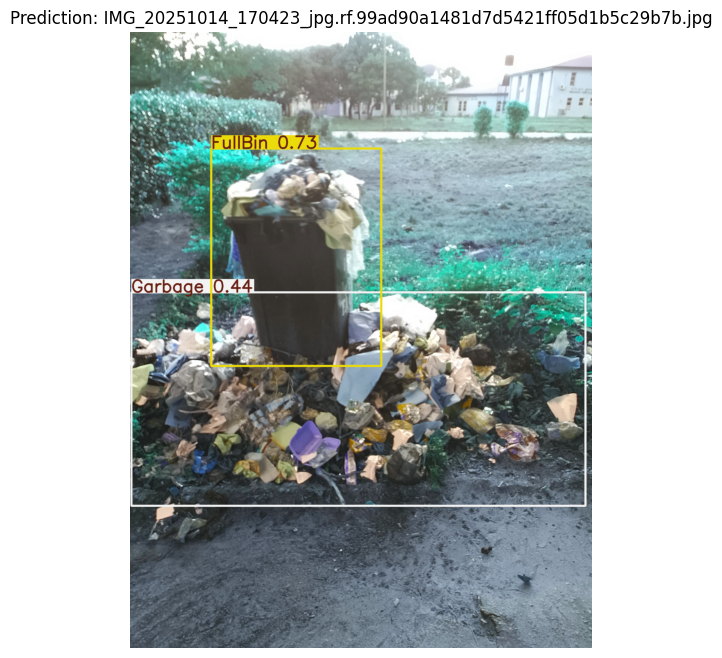

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/IMG_20251014_170423_jpg.rf.99ad90a1481d7d5421ff05d1b5c29b7b.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/potholes539_png_jpg.rf.f7e7b661ee28327c1061a586029bdf6f.jpg: 640x640 1 pothole, 9.9ms
Speed: 1.7ms preprocess, 9.9ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


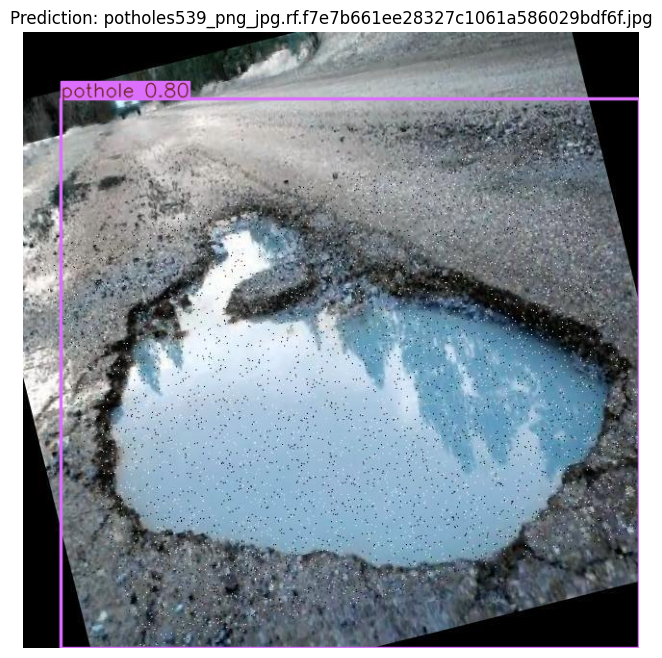

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/potholes539_png_jpg.rf.f7e7b661ee28327c1061a586029bdf6f.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/IMG_20251025_145745_jpg.rf.0ac2292eba83041f3bb2a51a83ee6255.jpg: 640x480 1 FullBin, 9.9ms
Speed: 2.8ms preprocess, 9.9ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)


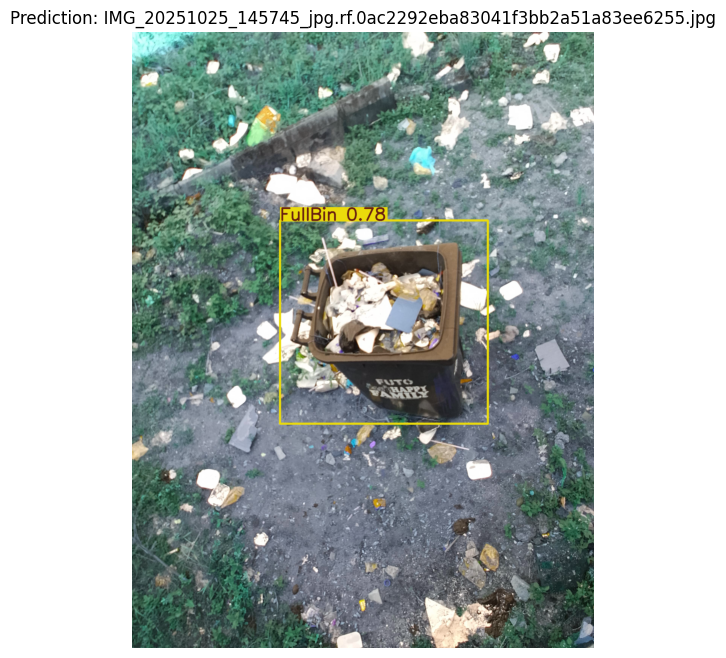

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/IMG_20251025_145745_jpg.rf.0ac2292eba83041f3bb2a51a83ee6255.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/WhatsApp-Image-2025-12-04-at-10_34_59-PM-1-_jpeg.rf.4cfdff35628e607b13d10a53492ea164.jpg: 320x640 8 ManagedBins, 48.3ms
Speed: 1.7ms preprocess, 48.3ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 640)


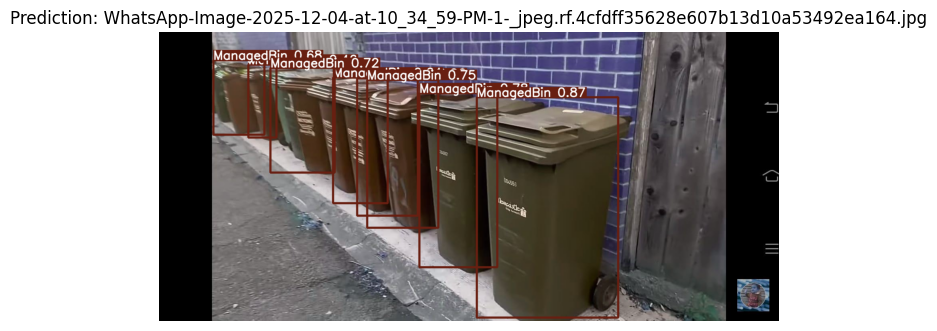

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/WhatsApp-Image-2025-12-04-at-10_34_59-PM-1-_jpeg.rf.4cfdff35628e607b13d10a53492ea164.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/fc15_1684_jpg.rf.865011ffab31f4910a64be66e053f318.jpg: 640x640 1 DefectedManhole, 9.7ms
Speed: 1.6ms preprocess, 9.7ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)


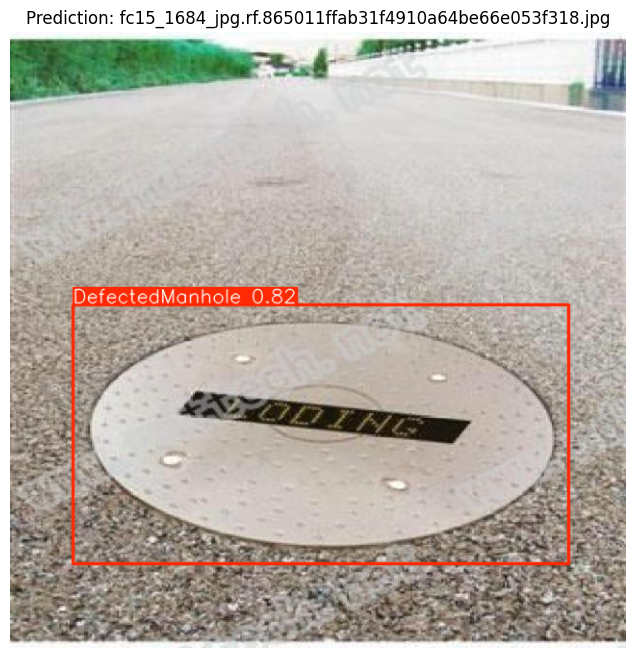

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/fc15_1684_jpg.rf.865011ffab31f4910a64be66e053f318.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/istockphoto-1302353269-612x612_jpg.rf.f8681dcc77c3c4299dc46bc7e93c1eb7.jpg: 480x640 1 FullBin, 45.9ms
Speed: 2.0ms preprocess, 45.9ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)


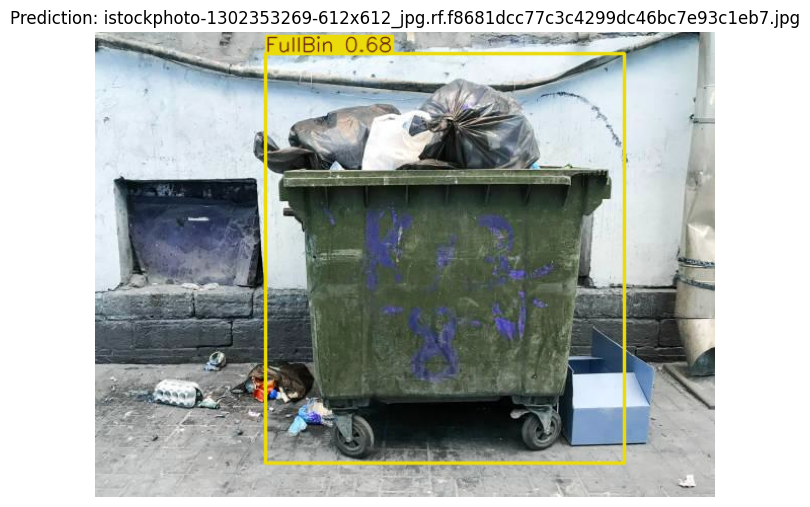

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/istockphoto-1302353269-612x612_jpg.rf.f8681dcc77c3c4299dc46bc7e93c1eb7.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/IMG_20250704_120325_jpg.rf.da5a8bd3bfadf05f0028996506afa371.jpg: 480x640 1 Garbage, 9.2ms
Speed: 2.9ms preprocess, 9.2ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)


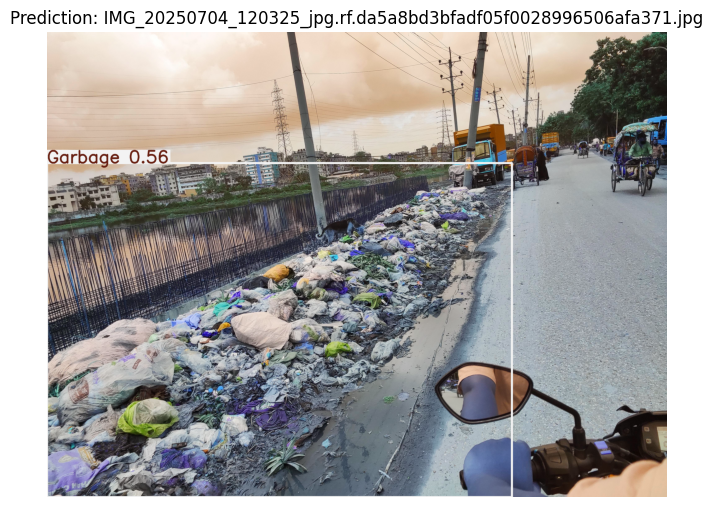

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/IMG_20250704_120325_jpg.rf.da5a8bd3bfadf05f0028996506afa371.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/istockphoto-577342592-612x612_jpg.rf.b504f5b32d2f9f1a1fbb0246fdb064f5.jpg: 448x640 1 ManagedBin, 46.6ms
Speed: 2.0ms preprocess, 46.6ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)


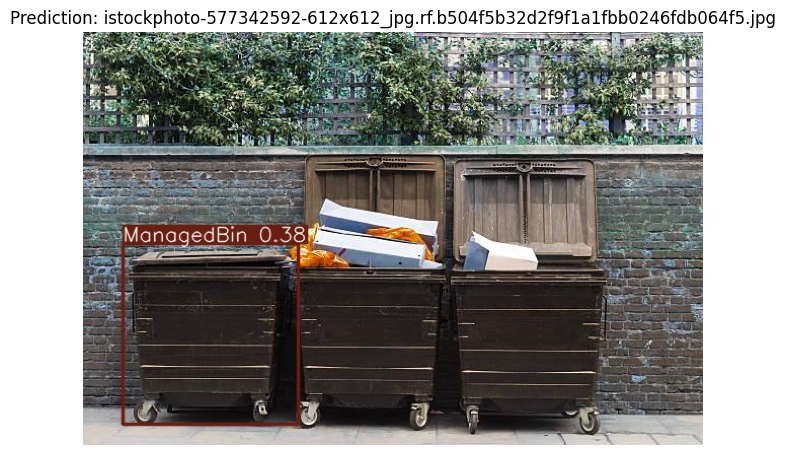

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/istockphoto-577342592-612x612_jpg.rf.b504f5b32d2f9f1a1fbb0246fdb064f5.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/istockphoto-537865876-612x612_jpg.rf.85646b855f9f1eaaefadf3ac1d63e027.jpg: 640x448 1 FullBin, 1 Garbage, 1 ManagedBin, 46.7ms
Speed: 1.8ms preprocess, 46.7ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 448)


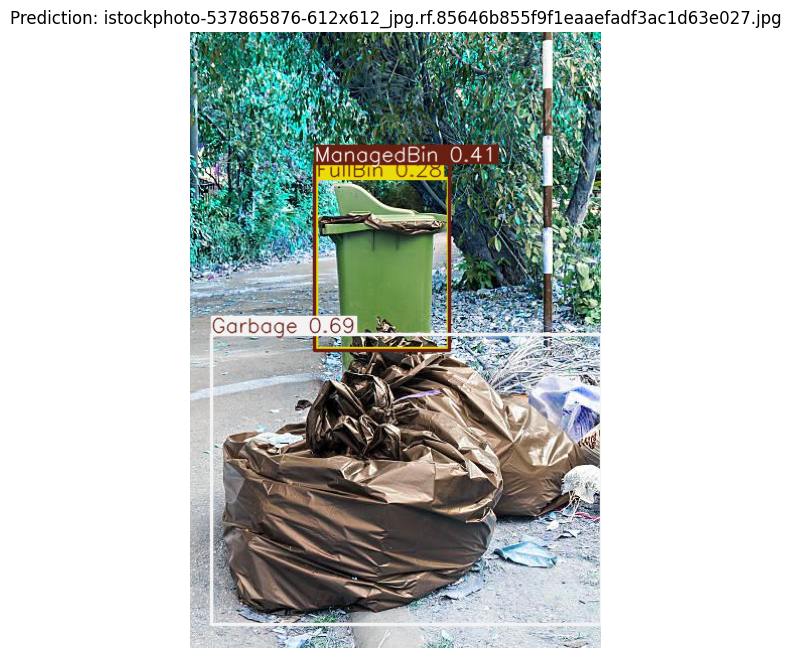

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/istockphoto-537865876-612x612_jpg.rf.85646b855f9f1eaaefadf3ac1d63e027.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/1406_jpg.rf.a04f9f813d0a14931960859ff76bc7e1.jpg: 640x640 1 DefectedManhole, 10.0ms
Speed: 1.5ms preprocess, 10.0ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)


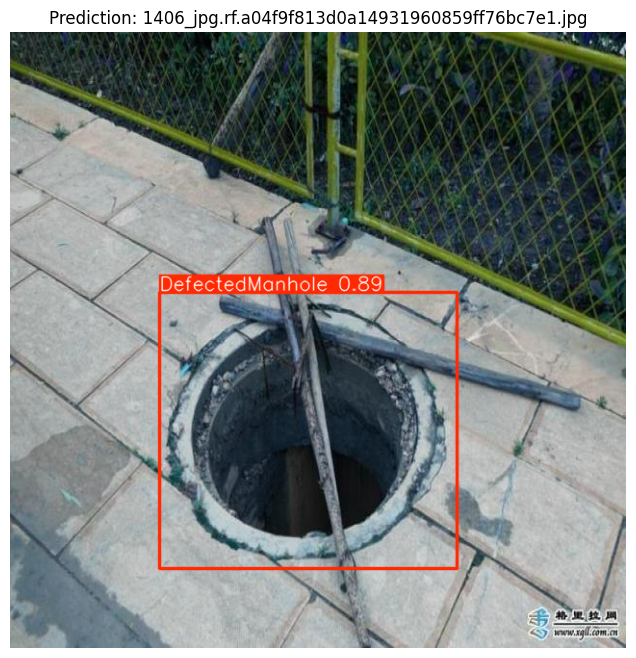

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/1406_jpg.rf.a04f9f813d0a14931960859ff76bc7e1.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/fc15_7115_jpg.rf.c5facb5ba4e9c63f408b4be586e895e8.jpg: 640x640 1 GoodManhole, 12.0ms
Speed: 1.9ms preprocess, 12.0ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


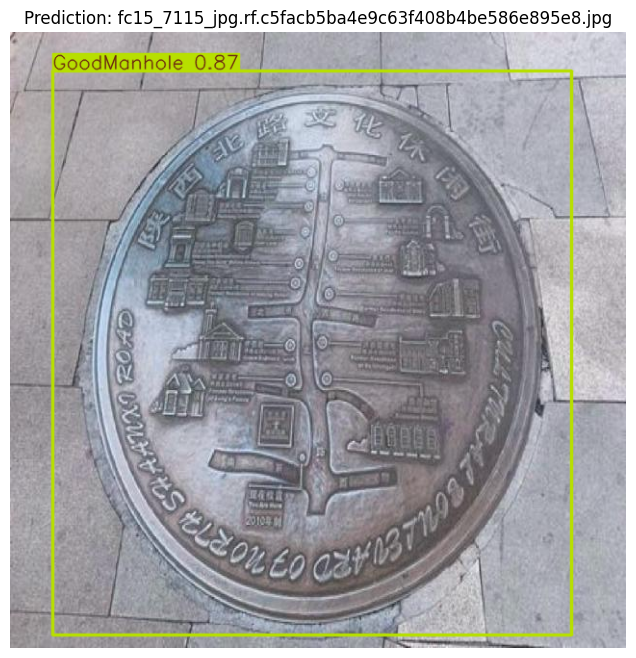

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/fc15_7115_jpg.rf.c5facb5ba4e9c63f408b4be586e895e8.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/fc15_2437_jpg.rf.5ab5068cec51dffefbb4fdbb1ebd8cec.jpg: 640x640 1 DefectedManhole, 10.5ms
Speed: 1.6ms preprocess, 10.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


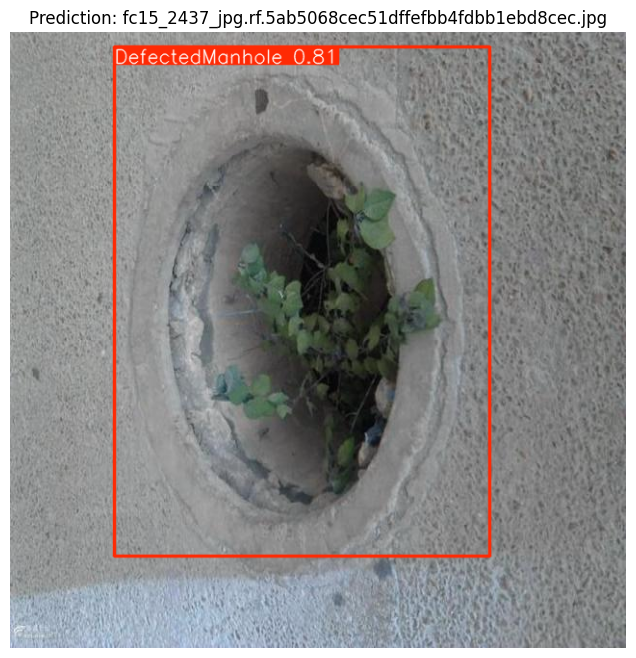

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/fc15_2437_jpg.rf.5ab5068cec51dffefbb4fdbb1ebd8cec.jpg

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/potholes73_png_jpg.rf.ebb72e997dab53997c90c183cf07a20d.jpg: 640x640 3 potholes, 9.4ms
Speed: 1.6ms preprocess, 9.4ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


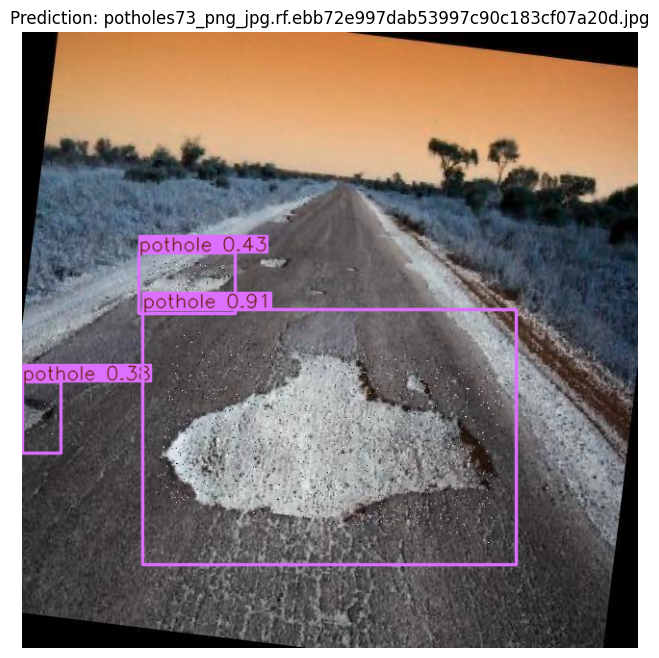

   ✓ Saved prediction: runs/detect/monitoring-yolo11s-improved/random_predictions/potholes73_png_jpg.rf.ebb72e997dab53997c90c183cf07a20d.jpg

✅ Random 10 predictions visualized and saved at: runs/detect/monitoring-yolo11s-improved/random_predictions


In [9]:
import random
import matplotlib.pyplot as plt
from PIL import Image
import os

# Load the best trained model
best_model = YOLO(f"{results_dir}/weights/best.pt")

# Path to test images (from your dataset)
test_images_dir = f"{dataset.location}/test/images"  # adjust if different
all_images = [os.path.join(test_images_dir, img) for img in os.listdir(test_images_dir) if img.endswith(('.jpg', '.png', '.jpeg'))]

# Select 10 random images
random_images = random.sample(all_images, 20)

# Create a directory to save prediction results
pred_save_dir = f"{results_dir}/random_predictions"
os.makedirs(pred_save_dir, exist_ok=True)

print("\n📌 Generating Random Predictions...")

for img_path in random_images:
    # Run prediction
    results = best_model.predict(source=img_path, conf=0.25, iou=0.6, save=False, show=False)
    
    # Get prediction image
    pred_img = results[0].plot()  # returns numpy array with boxes & labels drawn
    
    # Display image using matplotlib
    plt.figure(figsize=(8, 8))
    plt.imshow(pred_img)
    plt.axis('off')
    plt.title(f"Prediction: {os.path.basename(img_path)}")
    plt.show()
    
    # Save the prediction image
    save_path = os.path.join(pred_save_dir, os.path.basename(img_path))
    Image.fromarray(pred_img).save(save_path)
    print(f"   ✓ Saved prediction: {save_path}")

print("\n✅ Random 10 predictions visualized and saved at:", pred_save_dir)


In [10]:
from ultralytics import YOLO
import os
import shutil

# Load trained model
model_path = "runs/detect/monitoring-yolo11s-improved/weights/best.pt"
model = YOLO(model_path)

# Dataset paths
base = dataset.location
test_image_dir = f"{base}/test/images"

# Output folder for best predictions
output_dir = "best_predictions"
os.makedirs(output_dir, exist_ok=True)

class_names = ['DefectedManhole', 'FullBin', 'Garbage', 'GoodManhole', 'ManagedBin', 'pothole']
max_per_class = 5

# Keep count of saved images
saved = {cls: 0 for cls in class_names}

print("🔍 Generating predictions...")

# Loop through all test images
for img_name in os.listdir(test_image_dir):
    if not img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
        continue
    
    img_path = os.path.join(test_image_dir, img_name)
    
    # Predict
    results = model.predict(img_path, conf=0.25)[0]
    
    # If object detected
    for box in results.boxes:
        cls_id = int(box.cls)
        cls_name = class_names[cls_id]

        # Check if quota (10) reached
        if saved[cls_name] >= max_per_class:
            continue
        
        # Create class-wise folder
        cls_folder = os.path.join(output_dir, cls_name)
        os.makedirs(cls_folder, exist_ok=True)
        
        # Save annotated prediction image
        save_path = os.path.join(cls_folder, f"{saved[cls_name]}_{img_name}")
        results.save(filename=save_path)

        saved[cls_name] += 1

    # Stop early if all classes collected 10 images
    if all(count >= max_per_class for count in saved.values()):
        break

print("\n🎉 DONE! Best predictions saved in:")
print(output_dir)

print("\n📌 Images saved per class:")
for cls in class_names:
    print(f"   {cls}: {saved[cls]} images")


🔍 Generating predictions...

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/IMG_20250821_161040_jpg.rf.b08d700fde686d2ebe736f64636c4ce8.jpg: 640x480 1 Garbage, 9.9ms
Speed: 3.0ms preprocess, 9.9ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/istockphoto-577342592-612x612_jpg.rf.b504f5b32d2f9f1a1fbb0246fdb064f5.jpg: 448x640 1 ManagedBin, 10.3ms
Speed: 2.7ms preprocess, 10.3ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/fc15_0145_jpg.rf.8e2de067a262ba76c8b650fe20e869c5.jpg: 640x640 1 DefectedManhole, 1 GoodManhole, 9.7ms
Speed: 1.4ms preprocess, 9.7ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/working/Smart-city(latest)-4/test/images/istockphoto-1087532300-612x612_jpg.rf.e2f96a2ed5d1a29dd96a3218dc457c33.jpg: 448x640 2 FullBins, 3 Garbages, 9.3ms
Speed: 1.8ms preprocess, 9.3ms i